In [40]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from graphviz import Digraph

In [50]:
class Value:
    def __init__(self, data, _children = (), _op = '', label = ''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self.grad = 0.0
        self._backward = lambda: None
   
    def __repr__(self):
        return f"Value({self.data})"
   
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")
        def _backward():
            self.grad += out.grad*1.0
            other.grad += out.grad*1.0
        out._backward = _backward
        return out

    def __radd__(self, other):
        return self + other

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out =  Value(self.data * other.data, (self, other), "*")
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "Pow operation supports either ints or floats"
        out = Value(self.data**other, (self,) , f"**{other}")
        def _backward():
            self.grad = other*(self.data**(other-1))*out.grad
        out._backward = _backward
        return out
    
    def __rmul__(self, other):
        return self * other

    def __truediv__(self, other):
        return self*other**-1

    def __neg__(self):
        return self*-1

    def __sub__(self, other):
        return self + (-other)
    
    
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1 )/(math.exp(2*x) + 1)
        out = Value(t, (self, ), "tanh")
        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out
    def exp(self):
        x = self.data
        e = math.exp(x)
        out = Value (e, (self, ), "exp")
        def _backward():
            self.grad += out.data* out.grad
        out._backward = _backward
        return out   
    
    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

In [42]:
def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges
def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name= uid, label = "{%s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            dot.node(name= uid + n._op, label = n._op)
            dot.edge(uid + n._op, uid)
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op) 

    return dot

In [43]:
"""a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a * b; e.label='e'
d = e + c; d.label='d'
f = Value(-2.0, label='f')
L = d * f; L.label='L'
L.grad = 1.0
f.grad = d.data
d.grad = f.data
e.grad = d.grad * 1.0
c.grad = d.grad * 1.0
a.grad = e.grad * b.data
b.grad = e.grad * a.data
draw_dot(L)

a.data += a.grad*0.01
b.data += b.grad*0.01
c.data += c.grad*0.01
f.data += f.grad*0.01
e = a * b
d = e + c
L = d * f
print(L.data)"""

"a = Value(2.0, label='a')\nb = Value(-3.0, label='b')\nc = Value(10.0, label='c')\ne = a * b; e.label='e'\nd = e + c; d.label='d'\nf = Value(-2.0, label='f')\nL = d * f; L.label='L'\nL.grad = 1.0\nf.grad = d.data\nd.grad = f.data\ne.grad = d.grad * 1.0\nc.grad = d.grad * 1.0\na.grad = e.grad * b.data\nb.grad = e.grad * a.data\ndraw_dot(L)\n\na.data += a.grad*0.01\nb.data += b.grad*0.01\nc.data += c.grad*0.01\nf.data += f.grad*0.01\ne = a * b\nd = e + c\nL = d * f\nprint(L.data)"

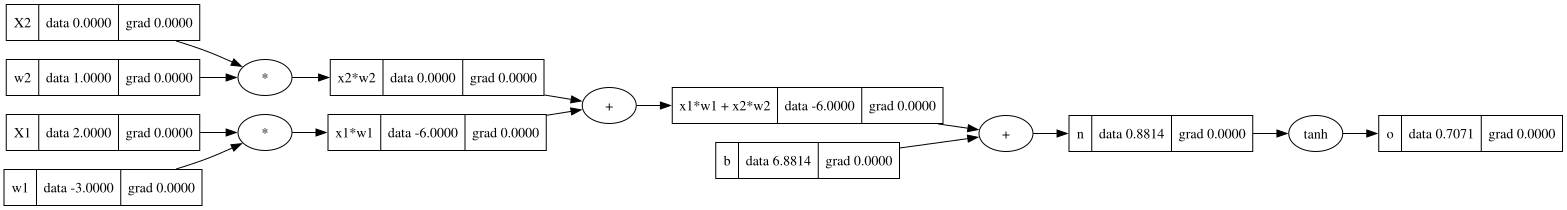

In [44]:
X1 = Value(2.0, label='X1')
X2 = Value(0.0, label='X2')
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.8813735870195432, label='b')
x1w1 = X1 * w1; x1w1.label='x1*w1'
x2w2 = X2 * w2; x2w2.label='x2*w2'
x1w1_plus_x2w2 = x1w1 + x2w2; x1w1_plus_x2w2.label='x1*w1 + x2*w2'
n = x1w1_plus_x2w2 + b; n.label='n'
o = n.tanh(); o.label = "o"
draw_dot(o)

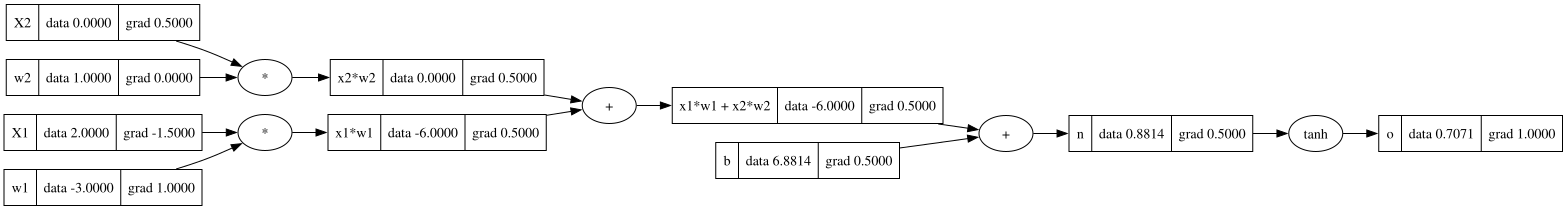

In [45]:
o.backward()
draw_dot(o)

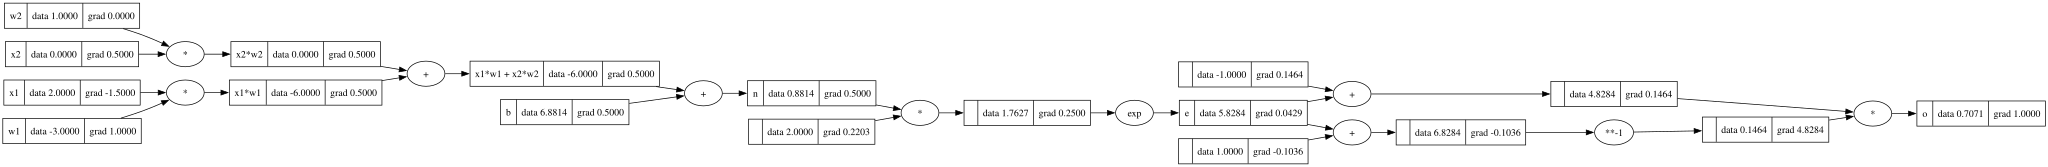

In [46]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.8813735870195432, label='b')
x1w1 = x1 * w1; x1w1.label='x1*w1'
x2w2 = x2 * w2; x2w2.label='x2*w2'
x1w1_plus_x2w2 = x1w1 + x2w2; x1w1_plus_x2w2.label='x1*w1 + x2*w2'
n = x1w1_plus_x2w2 + b; n.label='n'
e = (2*n).exp(); e.label = "e"
o = (e-1)/(e+1); o.label = "o"
o.backward()
draw_dot(o)


In [47]:
import torch

x1 = torch.Tensor([2.0]).double(); x1.requires_grad = True
x2 = torch.Tensor([0.0]).double(); x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double(); w1.requires_grad = True
w2 = torch.Tensor([1.0]).double(); w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double(); b.requires_grad = True
n = x1 * w1 + x2 * w2 + b
o = torch.tanh(n)
print(o.data.item())
o.backward()
print("----")
print(x1.grad.item())
print(x2.grad.item())
print(w1.grad.item())
print(w2.grad.item())

0.7071066904050358
----
-1.5000003851533106
0.5000001283844369
1.0000002567688737
0.0


In [48]:
import random

In [101]:
class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1, 1)) for _ in range (nin)]
        self.b = Value(random.uniform(-1, 1))

    def __call__(self, x):
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

class Layer:
    def __init__(self, nin, nout): ## nin -> basically number of weights, nout = number of neuorons in the layer
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x): ##nin -> number of
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts #to initialize with the input
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))] #create layers while iterating, the o/p of the first layer becomes the i/p of the next
        #that is Layer(nin, nout1), Layer(nout1, nin) -> what happens here is now the input dimension is not x dimension but it matches the num of outputs of 1st layer
    def __call__(self, x):
        for layer in self.layers:
            x = layer(x) #in every iteration the output becomes the input and fed into the next layer which have correct dimension to take this input
        return x

x = [2.0, 3.0]
n = MLP(2, [3, 4, 1])
"""
#When I run something like this what happens is that the first layers are created w 3 and 4 neurons respectively
first layer takes the input with w1,w2 and creates 3 outputs corresponding to 3 o/ps in layer 2
second layer takes the output of this layer of 3 neurons and inputs them into the layer of 4 neurons
last layer combines them in 1 neuron and gives the output
"""
n(x)


Value(-0.8733414222775382)

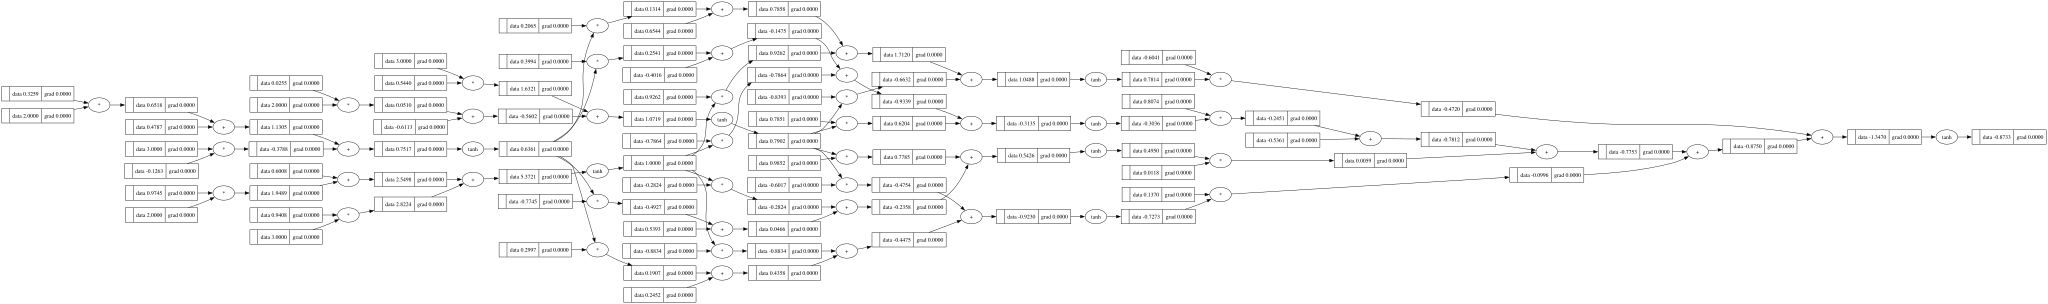

In [102]:
draw_dot(n(x))